# Laboratorio 17: Árbol de decisión para clasificar las especies de Iris

**Asignatura:** Analítica de Datos  
**Docente:** Luis Miguel Gómez Meneses  
**Universidad Cooperativa de Colombia**

## Objetivo

Construir un árbol de decisión para predecir la especie de una flor
a partir de sus medidas, interpretar sus reglas y evaluar sus predicciones.

Trabajaremos con tres clases: **setosa, versicolor y virginica**.

## Ruta de trabajo

1. Cargar y explorar los datos.
2. Definir las variables de entrada y la variable objetivo.
3. Separar entrenamiento y prueba.
4. Entrenar un árbol con profundidad máxima de 3.
5. Visualizar e interpretar sus reglas.
6. Evaluar las predicciones.
7. Escribir una conclusión propia.

## 1. Importación de librerías

Utilizaremos:

- **Pandas:** organizar y explorar los datos.
- **Matplotlib:** visualizar el árbol y la matriz de confusión.
- **Scikit-learn:** cargar Iris, separar los datos, entrenar el modelo y evaluarlo.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
SEMILLA = 42

## 2. Carga y exploración de los datos

Iris contiene **150 flores de tres especies**. Cada fila representa una flor.

Las variables medidas, en centímetros, son:

- Longitud del sépalo.
- Ancho del sépalo.
- Longitud del pétalo.
- Ancho del pétalo.

La columna **especie** indica la clase real que queremos predecir.

In [3]:
iris = load_iris()
columnas = [
    "longitud_sepalo",
    "ancho_sepalo",
    "longitud_petalo",
    "ancho_petalo"
]
datos = pd.DataFrame(iris.data, columns=columnas)
datos["especie"] = iris.target_names[iris.target]
display(datos.head())
print(f"Número de flores: {datos.shape[0]}")
print(f"Número de columnas: {datos.shape[1]}")
print("\nCantidad de flores por especie:")
print(datos["especie"].value_counts())
print("\nValores faltantes por columna:")
print(datos.isna().sum())

,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Número de flores: 150
Número de columnas: 5

Cantidad de flores por especie:
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Valores faltantes por columna:
longitud_sepalo    0
ancho_sepalo       0
longitud_petalo    0
ancho_petalo       0
especie            0
dtype: int64


### Preguntas de análisis

1. ¿Qué representa cada fila de la tabla?
2. ¿Cuántas variables de entrada tenemos y cuál es la variable objetivo?
3. ¿Las tres especies tienen la misma cantidad de observaciones?
4. ¿Es necesario tratar valores faltantes? Justifica con la salida del código.

**Respuestas:**

1.
2.
3.
4.

## 3. Variables y separación de los datos

- **X:** las cuatro medidas de cada flor.
- **y:** la especie que queremos predecir.

Dividiremos las observaciones en:

- **80 % para entrenamiento:** aprender las reglas del árbol.
- **20 % para prueba:** evaluar sus predicciones.

Usamos `stratify=y` para conservar las proporciones de las especies
y una semilla fija para reproducir la división.

La especie se utiliza como respuesta durante el entrenamiento,
pero no se incluye entre las entradas.

In [4]:
X = datos[columnas].copy()
y = datos["especie"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y
)
print("Dimensiones de las entradas:")
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
distribucion = pd.DataFrame({
    "Entrenamiento": y_train.value_counts(),
    "Prueba": y_test.value_counts()
}).reindex(iris.target_names)

display(distribucion)

Dimensiones de las entradas:
Entrenamiento: (120, 4)
Prueba: (30, 4)


,Entrenamiento,Prueba
especie,,
setosa,40,10
versicolor,40,10
virginica,40,10


## 4. Entrenamiento del árbol de decisión

Construiremos un árbol con profundidad máxima de **3**:
cada recorrido desde la raíz hasta una hoja tendrá como máximo
tres decisiones.

El método `fit()` aprende las reglas usando únicamente
las flores de entrenamiento.

Usaremos Gini como criterio para elegir las divisiones.

In [5]:
arbol = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=SEMILLA
)
arbol.fit(X_train, y_train)
print("Modelo entrenado.")
print("Profundidad alcanzada:", arbol.get_depth())
print("Número de hojas:", arbol.get_n_leaves())
print("Clases del modelo:", arbol.classes_)

Modelo entrenado.
Profundidad alcanzada: 3
Número de hojas: 5
Clases del modelo: ['setosa' 'versicolor' 'virginica']


## 5. Predicción y evaluación del modelo

Usaremos el árbol entrenado para predecir las especies de las flores
reservadas para prueba.

Compararemos las predicciones con las especies reales mediante:

- **Exactitud:** proporción de flores clasificadas correctamente.
- **Matriz de confusión:** muestra los aciertos y las confusiones entre especies.

En la matriz, las filas representan las especies reales y las columnas,
las especies predichas. Los aciertos están en la diagonal.

,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo,especie_real,especie_predicha,acierto
38,4.4,3.0,1.3,0.2,setosa,setosa,True
127,6.1,3.0,4.9,1.8,virginica,virginica,True
57,4.9,2.4,3.3,1.0,versicolor,versicolor,True
93,5.0,2.3,3.3,1.0,versicolor,versicolor,True
42,4.4,3.2,1.3,0.2,setosa,setosa,True
56,6.3,3.3,4.7,1.6,versicolor,versicolor,True
22,4.6,3.6,1.0,0.2,setosa,setosa,True
20,5.4,3.4,1.7,0.2,setosa,setosa,True
147,6.5,3.0,5.2,2.0,virginica,virginica,True
84,5.4,3.0,4.5,1.5,versicolor,versicolor,True


Aciertos: 29 de 30
Errores: 1
Exactitud en prueba: 96.67%


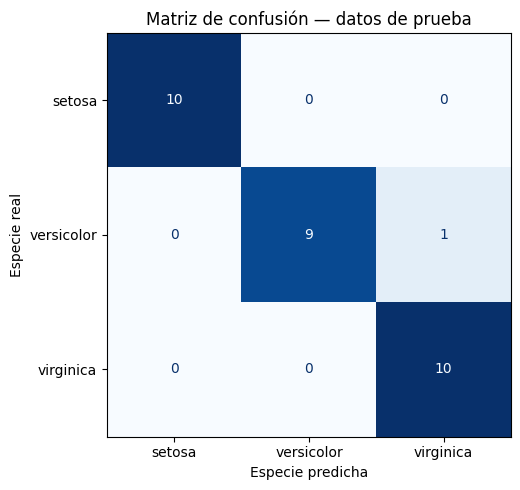

In [8]:
y_pred = arbol.predict(X_test)
resultados = X_test.copy()
resultados["especie_real"] = y_test
resultados["especie_predicha"] = y_pred
resultados["acierto"] = (
    resultados["especie_real"] == resultados["especie_predicha"]
)
display(resultados.head(10))
aciertos = int(resultados["acierto"].sum())
total = len(y_test)
exactitud = accuracy_score(y_test, y_pred)
print(f"Aciertos: {aciertos} de {total}")
print(f"Errores: {total - aciertos}")
print(f"Exactitud en prueba: {exactitud:.2%}")
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=arbol.classes_,
    display_labels=arbol.classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Matriz de confusión — datos de prueba")
ax.set_xlabel("Especie predicha")
ax.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

### Pregunta de análisis

Observa la matriz de confusión:

1. ¿Cuántas flores clasificó correctamente el árbol de las 30 evaluadas?
2. En la única clasificación incorrecta, ¿cuál era la especie real
   y cuál predijo el modelo?
3. Explica qué significa una exactitud del 96,67 %.
   ¿Este resultado garantiza el mismo desempeño con otras flores?
   Justifica.

**Respuesta:**

Escribe aquí tu análisis.

## 7. Conclusión del laboratorio

Escribe un párrafo de entre 5 y 8 líneas que explique:

- Qué buscaba predecir el modelo y qué variables utilizó.
- Qué resultado obtuvo en las 30 flores de prueba.
- Qué confusión entre especies identificaste.
- Por qué es importante evaluar con datos diferentes de los usados
  para entrenar.
- Por qué este resultado no garantiza el mismo desempeño
  con todas las flores nuevas.

Relaciona tus afirmaciones con los resultados del notebook.
No te limites a decir que “el modelo funcionó bien”.

**Mi conclusión:**

Escribe aquí tu conclusión.